# M18K V2 — WB-only Inference on Random Test Images

**Demo:** Run the trained WB-only YOLOv8n-seg on a reproducible random sample of **10 or 50 RGB test images** already stored in Google Drive. No image uploads, training, COCO parsing, or dataset conversion.

Run cells top to bottom in **Google Colab**. In the configuration cell, set `SAMPLE_SIZE = 10` or `50`.

Outputs: clean mask-overlay previews, optional bounding boxes/confidence labels, mushroom counts, predicted instance-mask areas in **px²**, per-instance CSV, per-image summary CSV, and a ZIP of results.

**Note:** Pixel area is *not* physical area in mm², and predicted counts/areas are not automatically ground-truth-accurate.

## 1. Install dependencies

In [7]:
%pip -q install "ultralytics>=8.4,<9" "gdown>=5,<6" pandas opencv-python matplotlib

## 2. Configuration and WB-only checkpoint

Uses [Khang's WB-only `best.pt`](https://drive.google.com/file/d/1Q5iq_-j-RwOTkyiiXyTOc80Cf_xwk7K-/view) and reads existing test images from:

`/content/drive/MyDrive/M18K_Reproduction/M18K_V2_data/M18KV2/test/rgb`

Set `SAMPLE_SIZE` to **10** or **50**. The same random seed selects the same image filenames each time. If your shared Google Drive folder resolves to a different path, change `INPUT_FOLDER` below.

In [8]:
from pathlib import Path
import json, math, hashlib, shutil
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import gdown
from IPython.display import display
from ultralytics import YOLO

# --- Adjust only these settings if needed ---
MODEL_FILE_ID = "1Q5iq_-j-RwOTkyiiXyTOc80Cf_xwk7K-"
MODEL_PATH_OVERRIDE = ""    # e.g. "/content/drive/MyDrive/.../best.pt"
INPUT_FOLDER = "/content/drive/MyDrive/M18K_Reproduction/M18K_V2_data/M18KV2/test/rgb"
SAMPLE_SIZE = 10            # Choose 10 or 50 random TEST images
RANDOM_SEED = 42
OUTPUT_ROOT = Path("/content/M18K_WB_Final_Results")

IMAGE_SIZE = 640
CONFIDENCE = 0.25
NMS_IOU = 0.70
MAX_DETECTIONS = 1000        # High enough for dense mushroom beds
MASK_ALPHA = 0.40
DRAW_BOXES = False           # Cleaner visuals in dense mushroom beds
DRAW_CONFIDENCE = False      # Confidence values remain in CSV
PREVIEW_IMAGES = 3
AUTO_DOWNLOAD_ZIP = False    # Change to True to trigger browser download

DEVICE = 0 if torch.cuda.is_available() else "cpu"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

if MODEL_PATH_OVERRIDE.strip():
    checkpoint = Path(MODEL_PATH_OVERRIDE).expanduser()
else:
    checkpoint = Path("/content/khang_wb_best.pt")
    if not checkpoint.exists():
        print("Downloading Khang's WB-only checkpoint...")
        downloaded = gdown.download(id=MODEL_FILE_ID, output=str(checkpoint), quiet=False)
        if downloaded is None or not checkpoint.is_file():
            raise FileNotFoundError(
                "Could not download the checkpoint. Check link permissions or upload "
                "best.pt and set MODEL_PATH_OVERRIDE."
            )

if not checkpoint.is_file():
    raise FileNotFoundError(f"Checkpoint not found: {checkpoint}")

model = YOLO(str(checkpoint))
print("Checkpoint:", checkpoint)
print("SHA-256:", hashlib.sha256(checkpoint.read_bytes()).hexdigest())
print("Classes:", model.names)
print("Device:", DEVICE)
if len(model.names) != 1 or str(model.names.get(0, "")).strip().lower() not in {"wb", "white button", "white_button"}:
    raise ValueError(f"Expected the single-class WB checkpoint; found: {model.names}")

Checkpoint: /content/khang_wb_best.pt
SHA-256: 93d993ec6b48c1fca9d59178afe11377ef20afa3ed0c304841e4d6b36d447961
Classes: {0: 'WB'}
Device: 0


## 3. Randomly select RGB images from your M18K V2 test split

The notebook mounts Google Drive if necessary, locates `test/rgb`, and selects `SAMPLE_SIZE` images deterministically (`RANDOM_SEED = 42`). It reads only the selected images. **No upload dialog.**

In [9]:
from pathlib import Path
import random
from google.colab import drive, files

folder = Path(INPUT_FOLDER).expanduser()
if not folder.is_dir():
    # First visit to Colab? Mount Google Drive and retry your existing path.
    drive.mount('/content/drive')

if not folder.is_dir():
    raise FileNotFoundError(
        f"Dataset RGB folder not visible: {folder}\n"
        "Check your Google Drive shortcut/mount, or change INPUT_FOLDER in Cell 2 "
        "to the actual path of M18KV2/test/rgb."
    )

SUPPORTED = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
all_images = sorted(
    p for p in folder.iterdir()
    if p.is_file() and p.suffix.lower() in SUPPORTED
)
if len(all_images) < SAMPLE_SIZE:
    raise ValueError(f'Only {len(all_images)} images found; SAMPLE_SIZE={SAMPLE_SIZE}')
if SAMPLE_SIZE not in (10, 50):
    raise ValueError('Choose SAMPLE_SIZE = 10 or 50 for this demo')

# Sampling without replacement, reproducible across sessions.
image_paths = sorted(random.Random(RANDOM_SEED).sample(all_images, SAMPLE_SIZE))

# Check just the selected images, not the entire 450-image test split.
readable = []
for p in image_paths:
    if cv2.imread(str(p)) is None:
        print('Unreadable image, skipped:', p.name)
    else:
        readable.append(p)
image_paths = readable
if not image_paths:
    raise ValueError('No readable images in the selected sample')

print(f'Selected {len(image_paths)} / {len(all_images)} test RGB images (seed={RANDOM_SEED})')
for p in image_paths[:10]:
    print(' •', p.name)


Mounted at /content/drive
Selected 10 / 450 test RGB images (seed=42)
 • 004058.png
 • 004098.png
 • 004103.png
 • 004117.png
 • 004160.png
 • 004171.png
 • 004186.png
 • 004373.png
 • 004423.png
 • 004425.png


## 4. Run instance segmentation, count mushrooms, and calculate mask areas

- Each detection corresponds to a predicted WB instance.
- **Area (px²)** is the number of foreground pixels in its binary mask at original image size.
- A mask-ID image is exported for inspection (`0` = background; `1, 2, ...` = instance IDs). Overlapping pixels take the last assigned ID; **CSV areas are calculated from individual masks before this overlap resolution**.
- The default preview hides crowded bounding boxes and confidence labels. Per-instance coordinates and confidence remain in `wb_instances.csv`.


In [10]:
ANNOTATED_DIR = OUTPUT_ROOT / "annotated"
MASK_ID_DIR = OUTPUT_ROOT / "mask_ids"
for d in (ANNOTATED_DIR, MASK_ID_DIR):
    if d.exists():
        shutil.rmtree(d)  # clear old predictions when changing SAMPLE_SIZE
    d.mkdir(parents=True, exist_ok=True)


def mask_area_px2(binary_mask):
    """Visible projected area, counted at original image resolution."""
    return int(np.count_nonzero(binary_mask))


def color_for_instance(i):
    """Deterministic BGR colors for drawing, different for adjacent instances."""
    return (int(40 + (i * 97) % 190),
            int(45 + (i * 61) % 190),
            int(45 + (i * 131) % 190))


def extract_original_size_masks(result):
    """Ultralytics predicted masks as original-size boolean arrays."""
    h, w = result.orig_img.shape[:2]
    if result.masks is None:
        return []
    raw = result.masks.data.cpu().numpy()
    masks = []
    for data in raw:
        # retina_masks=True generally gives the original size, but verify it.
        if data.shape != (h, w):
            data = cv2.resize(data, (w, h), interpolation=cv2.INTER_NEAREST)
        masks.append(data > 0.5)
    return masks


instance_rows = []
image_rows = []
preview_items = []

predictions = model.predict(
    source=[str(p) for p in image_paths],
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE,
    iou=NMS_IOU,
    max_det=MAX_DETECTIONS,
    retina_masks=True,
    device=DEVICE,
    stream=True,
    verbose=False,
)

for result in predictions:
    original = result.orig_img.copy()  # BGR, original dimensions
    h, w = original.shape[:2]
    path = Path(result.path)
    image_key = f"{path.stem}_{path.suffix.lower().lstrip('.')}"

    boxes = result.boxes
    n_boxes = 0 if boxes is None else len(boxes)
    masks = extract_original_size_masks(result)
    if n_boxes != len(masks):
        raise RuntimeError(
            f"Box/mask count mismatch for {path.name}: {n_boxes} boxes, {len(masks)} masks"
        )

    composite = original.copy()
    id_map = np.zeros((h, w), dtype=np.uint16)
    union_mask = np.zeros((h, w), dtype=bool)
    area_values = []
    draw_info = []

    for i, mask in enumerate(masks):
        area = mask_area_px2(mask)
        color = color_for_instance(i)
        composite[mask] = color
        id_map[mask] = i + 1
        union_mask |= mask

        xyxy = boxes.xyxy[i].cpu().numpy().tolist()
        conf = float(boxes.conf[i].item())
        x1, y1, x2, y2 = [float(v) for v in xyxy]
        area_values.append(area)
        draw_info.append((mask, (x1, y1, x2, y2), conf, color))

        instance_rows.append({
            "image": path.name,
            "instance_id": i + 1,
            "class": "WB",
            "confidence": round(conf, 6),
            "mask_area_px2": area,
            "equivalent_diameter_px": round(2.0 * math.sqrt(area / math.pi), 3),
            "bbox_x1": round(x1, 2),
            "bbox_y1": round(y1, 2),
            "bbox_x2": round(x2, 2),
            "bbox_y2": round(y2, 2),
        })

    annotated = cv2.addWeighted(composite, MASK_ALPHA, original, 1 - MASK_ALPHA, 0)
    for i, (mask, xyxy, confidence, color) in enumerate(draw_info):
        contours, _ = cv2.findContours(mask.astype(np.uint8),
                                       cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(annotated, contours, -1, color, 1)
        if DRAW_BOXES:
            x1, y1, x2, y2 = map(int, xyxy)
            cv2.rectangle(annotated, (x1, y1), (x2, y2), color, 1)
            if DRAW_CONFIDENCE:
                text = f"{i+1}:{confidence:.2f}"
                cv2.putText(annotated, text, (max(0, x1), max(12, y1 - 2)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.30, color, 1, cv2.LINE_AA)

    count = len(masks)
    label = f"WB count: {count}"
    cv2.rectangle(annotated, (8, 8), (200, 39), (20, 20, 20), -1)
    cv2.putText(annotated, label, (16, 30), cv2.FONT_HERSHEY_SIMPLEX,
                0.65, (255, 255, 255), 2, cv2.LINE_AA)

    # A 16-bit PNG keeps IDs >255 (dense images may have hundreds of instances).
    annotated_path = ANNOTATED_DIR / f"{image_key}_annotated.png"
    mask_path = MASK_ID_DIR / f"{image_key}_mask_ids.png"
    if not cv2.imwrite(str(annotated_path), annotated):
        raise OSError(f"Failed to save {annotated_path}")
    if not cv2.imwrite(str(mask_path), id_map):
        raise OSError(f"Failed to save {mask_path}")

    image_rows.append({
        "image": path.name,
        "image_width": w,
        "image_height": h,
        "wb_count": count,
        "sum_instance_mask_area_px2": int(sum(area_values)),
        "union_mask_area_px2": mask_area_px2(union_mask),
        "mean_instance_area_px2": round(float(np.mean(area_values)), 2) if area_values else 0.0,
        "median_instance_area_px2": round(float(np.median(area_values)), 2) if area_values else 0.0,
        "annotated_file": annotated_path.name,
        "mask_ids_file": mask_path.name,
    })

    if len(preview_items) < PREVIEW_IMAGES:
        preview_items.append((path.name, original, annotated))

    print(f"{path.name}: {count} WB instances; sum mask area = {sum(area_values):,} px²")

instances_df = pd.DataFrame(instance_rows, columns=[
    "image", "instance_id", "class", "confidence", "mask_area_px2",
    "equivalent_diameter_px", "bbox_x1", "bbox_y1", "bbox_x2", "bbox_y2"
])
images_df = pd.DataFrame(image_rows)
instances_df.to_csv(OUTPUT_ROOT / "wb_instances.csv", index=False)
images_df.to_csv(OUTPUT_ROOT / "wb_image_summary.csv", index=False)

settings = {
    "model_type": "YOLOv8n-seg WB-only",
    "checkpoint": str(checkpoint),
    "checkpoint_sha256": hashlib.sha256(checkpoint.read_bytes()).hexdigest(),
    "image_size": IMAGE_SIZE,
    "confidence_threshold": CONFIDENCE,
    "nms_iou_threshold": NMS_IOU,
    "max_det": MAX_DETECTIONS,
    "retina_masks": True,
    "area_unit": "pixel^2 at original image resolution",
    "device": str(DEVICE),
    "source_directory": INPUT_FOLDER,
    "sample_size_requested": SAMPLE_SIZE,
    "random_seed": RANDOM_SEED,
    "selected_image_filenames": [p.name for p in image_paths],
    "num_images": len(image_rows),
    "num_predicted_wb": len(instance_rows),
}
(OUTPUT_ROOT / "inference_settings.json").write_text(
    json.dumps(settings, indent=2), encoding="utf-8"
)
print("\nSaved results to:", OUTPUT_ROOT)
display(images_df[["image", "wb_count", "sum_instance_mask_area_px2", "union_mask_area_px2"]])

004058.png: 55 WB instances; sum mask area = 226,222 px²
004098.png: 163 WB instances; sum mask area = 506,103 px²
004103.png: 156 WB instances; sum mask area = 655,640 px²
004117.png: 85 WB instances; sum mask area = 249,309 px²
004160.png: 223 WB instances; sum mask area = 568,327 px²
004171.png: 203 WB instances; sum mask area = 799,857 px²
004186.png: 87 WB instances; sum mask area = 186,483 px²
004373.png: 159 WB instances; sum mask area = 848,762 px²
004423.png: 222 WB instances; sum mask area = 641,188 px²
004425.png: 198 WB instances; sum mask area = 777,803 px²

Saved results to: /content/M18K_WB_Final_Results


,image,wb_count,sum_instance_mask_area_px2,union_mask_area_px2
0,004058.png,55,226222,225034
1,004098.png,163,506103,497120
2,004103.png,156,655640,643362
3,004117.png,85,249309,246125
4,004160.png,223,568327,549912
5,004171.png,203,799857,781911
6,004186.png,87,186483,182404
7,004373.png,159,848762,829802
8,004423.png,222,641188,624246
9,004425.png,198,777803,766840


## 5. Preview sample images

Left: original RGB image. Right: predicted WB instance masks, mask outlines, and count. Dense mushroom beds look cleaner with boxes and confidence labels hidden. To show bounding boxes, change `DRAW_BOXES = True` in the configuration cell; to label boxes with ID and confidence, also enable `DRAW_CONFIDENCE = True`. Both remain available in the CSV regardless.


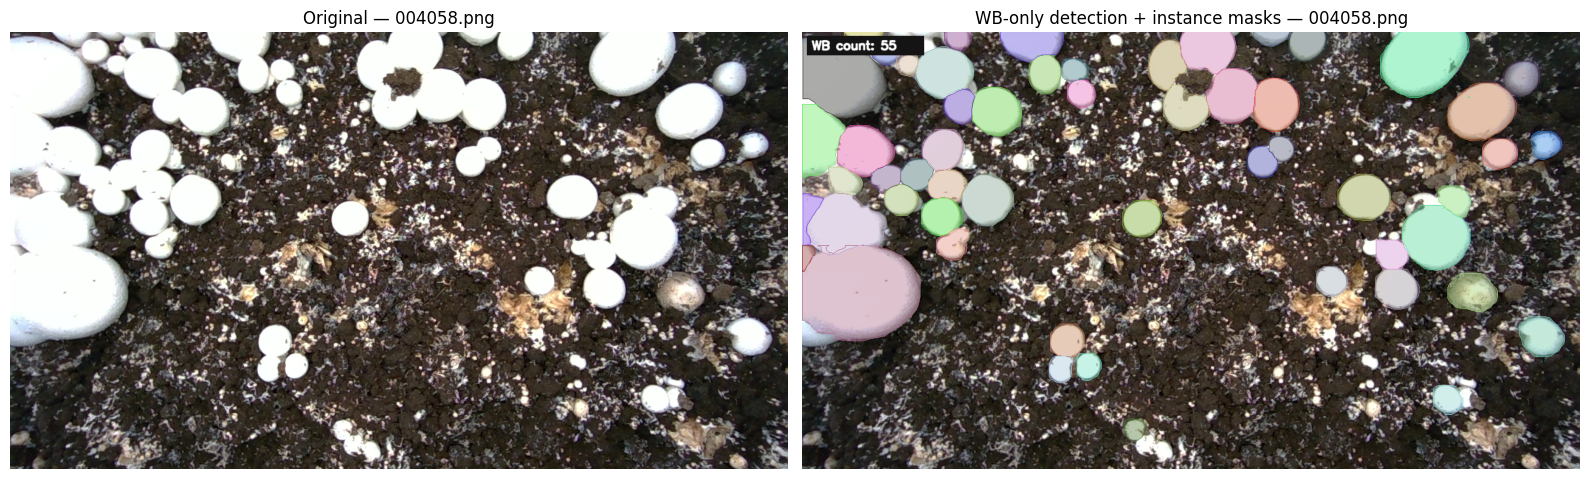

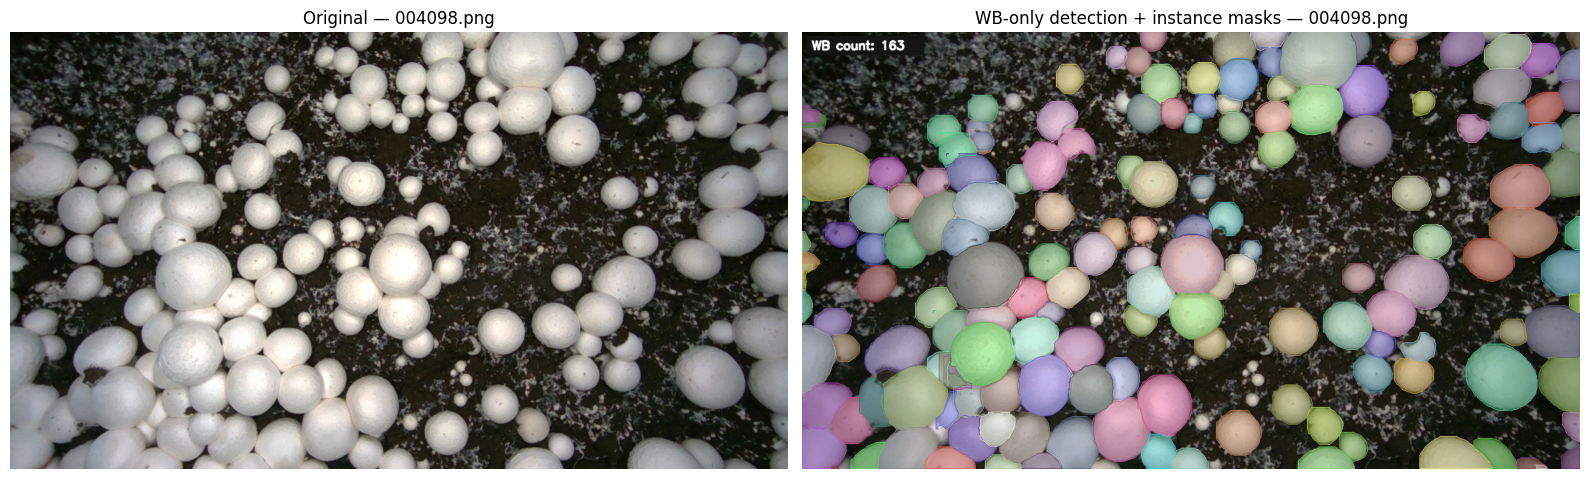

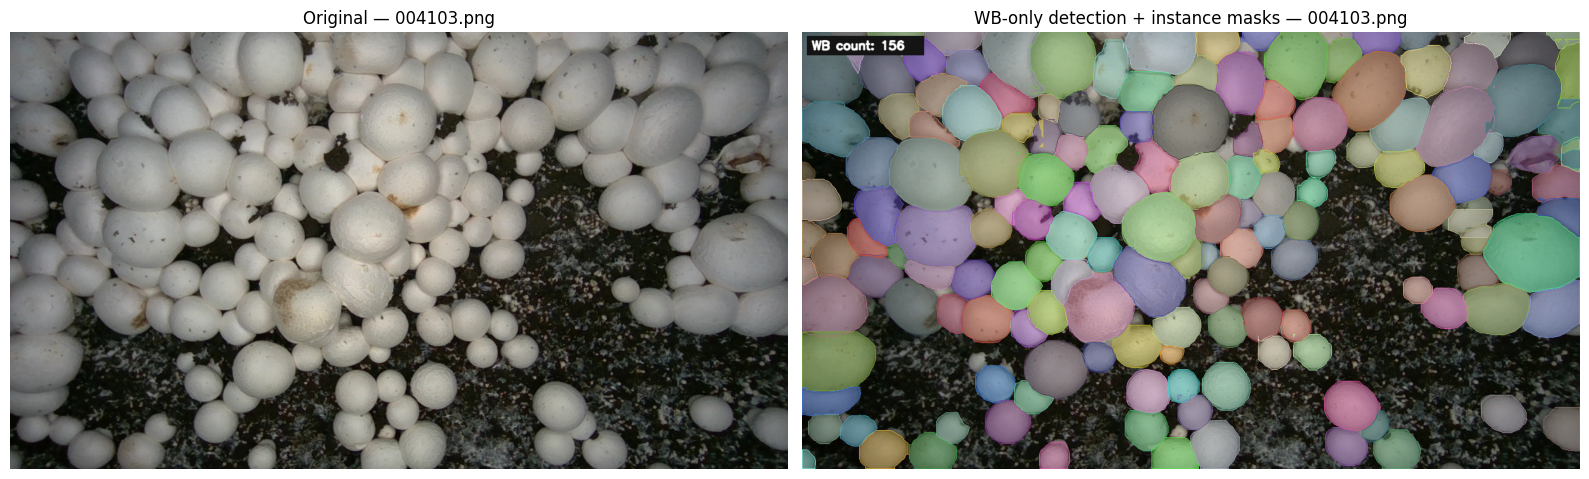

Images analyzed: 10
Total predicted WB instances: 1551
Mean predicted instance mask area: 3520.11 px²


,image,instance_id,class,confidence,mask_area_px2,equivalent_diameter_px,bbox_x1,bbox_y1,bbox_x2,bbox_y2
0,004058.png,1,WB,0.948408,14836,137.440,0.70,5.87,138.25,143.36
1,004058.png,2,WB,0.942258,25384,179.777,0.00,351.39,196.47,512.27
2,004058.png,3,WB,0.942219,3257,64.397,526.85,277.85,591.55,338.67
3,004058.png,4,WB,0.942146,12517,126.242,950.66,0.00,1097.32,109.50
4,004058.png,5,WB,0.938560,8317,102.905,1061.13,84.23,1175.45,180.38
5,004058.png,6,WB,0.930543,5657,84.869,262.20,235.45,348.48,320.44
6,004058.png,7,WB,0.930360,3415,65.940,195.02,273.62,263.13,337.61
7,004058.png,8,WB,0.929751,6143,88.439,664.75,60.18,749.89,152.03
8,004058.png,9,WB,0.929618,5336,82.426,880.32,234.92,968.71,311.28
9,004058.png,10,WB,0.927985,9343,109.068,986.21,285.54,1099.96,393.40


In [11]:
for filename, original, annotated in preview_items:
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    axes[0].imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Original — {filename}")
    axes[1].imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"WB-only detection + instance masks — {filename}")
    for ax in axes: ax.axis("off")
    plt.tight_layout()
    plt.show()

print("Images analyzed:", len(images_df))
print("Total predicted WB instances:", len(instances_df))
if len(instances_df):
    print("Mean predicted instance mask area:",
          round(float(instances_df['mask_area_px2'].mean()), 2), "px²")
    display(instances_df.head(12))

## 6. Export inference results

The ZIP contains annotated images, 16-bit mask-ID images, per-instance CSV, per-image summary CSV, and inference settings. Dataset RGB inputs are **not** included.

In [12]:
ZIP_PATH = Path("/content/M18K_WB_Final_Results.zip")
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

# Write only inference outputs; original M18K V2 RGB test images stay in Drive.
import zipfile
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in sorted(OUTPUT_ROOT.rglob("*")):
        if path.is_file() and path != ZIP_PATH:
            zf.write(path, arcname=str(path.relative_to(OUTPUT_ROOT)))

print("ZIP:", ZIP_PATH)
print("ZIP size: %.2f MB" % (ZIP_PATH.stat().st_size / (1024 * 1024)))
print("Per-instance CSV:", OUTPUT_ROOT / "wb_instances.csv")
print("Per-image CSV:", OUTPUT_ROOT / "wb_image_summary.csv")

if AUTO_DOWNLOAD_ZIP:
    files.download(str(ZIP_PATH))
else:
    print("To download in Colab, run: files.download(str(ZIP_PATH))")

ZIP: /content/M18K_WB_Final_Results.zip
ZIP size: 14.22 MB
Per-instance CSV: /content/M18K_WB_Final_Results/wb_instances.csv
Per-image CSV: /content/M18K_WB_Final_Results/wb_image_summary.csv
To download in Colab, run: files.download(str(ZIP_PATH))


## Notes for report/demo

- **Dataset:** M18K V2, random sample from the held-out **test/rgb** directory, selected by `RANDOM_SEED`.
- **Model:** existing WB-only YOLOv8n-seg checkpoint; inference only, no retraining.
- **Counts:** numbers of predicted WB masks after confidence threshold and NMS, which can differ from true mushroom counts.
- **Areas:** visible image-space predicted mask areas in **px²**, computed at original image resolution; no depth calibration or mm² conversion.
- **Accuracy:** the full held-out AP evaluation and GT-matched area-error evaluation were performed separately; this notebook is a demonstration, not a new accuracy benchmark.
- **Drive:** if the dataset folder is a shared shortcut that is not exposed in Colab, adjust `INPUT_FOLDER` to the mounted real folder; no image upload is required.